# SUNSHIELD — Notebook 2: Window Size & LSTM Training

**Place in Dr. Mai's workflow:** this notebook is the **"Training (LSTM) → gives predicted line"** box.
It produces the *predicted* `AC_POWER` line for train, validation and test. Notebook 3 then applies the
anomaly definition to the actual line and to this predicted line separately.

```
Dataset → Preprocessing → Split 70/15/15 → [ Training (LSTM) → predicted line ] → Anomaly definition (k) → F1 → best k
                         (Notebook 1)            (this notebook)                    (Notebook 3)       (Notebook 4)
```

| Step | What happens | Output |
|---|---|---|
| 1 | Window-size experiment (8, 16, 24, 32, 48) with the same settings and seed | results table + plot |
| 2 | Choose the window by validation loss, one-line justification | justification text |
| 3 | Build the LSTM: LSTM(64) → Dropout(0.2) → LSTM(32) → Dropout(0.2) → Dense(1) | `model.summary()` |
| 4 | Train on ALL training data (faults included); validation for early stopping | training log |
| 5 | Plot training vs validation loss and mark the best epoch | `loss_curve.png` |
| 6 | Predict `AC_POWER` for train / validation / test and convert back to kW | `prediction_train/val/test.csv` |
| 7 | RMSE and MAE (kW) for each split | metrics table |
| 8 | Save and zip outputs | `step2_outputs.zip` |

**Input:** `step1_outputs.zip`, the file downloaded at the end of Notebook 1.

## 0. Upload Notebook 1 outputs

Run the cell below, click **Choose Files** and select `step1_outputs.zip`.

In [ ]:
import shutil
from google.colab import files
uploaded = files.upload()
shutil.unpack_archive(list(uploaded)[0], 'step1_outputs', 'zip')

## Settings

In [ ]:
import os, shutil, time, joblib
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow C++ log messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 42
WINDOW_SIZES = [8, 16, 24, 32, 48]
TARGET_SHIFT = 1        # must be the same value as in Notebook 1
EPOCHS = 100            # upper limit; early stopping usually stops much earlier
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
PATIENCE = 10           # stop after 10 epochs without a better validation loss

# Same seed + deterministic operations = the same result every time the notebook runs
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

STEP1_DIR = 'step1_outputs'
OUT_DIR = 'step2_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style (light surface, recessive grid, 2 px lines)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))
print('Notebook 1 outputs:', sorted(os.listdir(STEP1_DIR)))

## Load Notebook 1 outputs and the window builder

`clean_data.csv` already has the scaled columns (`_z`), the `SPLIT` of every row and the `RUN_ID`
(unbroken stretch of one inverter). `build_windows` is copied unchanged from Notebook 1, so both notebooks
cut windows in exactly the same way.

In [2]:
clean = pd.read_csv(os.path.join(STEP1_DIR, 'clean_data.csv'), parse_dates=['DATE_TIME'])
clean = clean.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
scalers = joblib.load(os.path.join(STEP1_DIR, 'scalers.pkl'))
target_scaler = scalers['target']

FEATURES, TARGET = scalers['feature_names'], scalers['target_name']
FEATURES_Z, TARGET_Z = [c + '_z' for c in FEATURES], TARGET + '_z'
SPLITS = ['train', 'val', 'test']
KW_PER_Z = target_scaler.scale_[0]      # 1 scaled unit of AC_POWER = this many kW

def build_windows(df, window, target_shift=TARGET_SHIFT, features=FEATURES_Z, target=TARGET_Z):
    '''Returns {split: (X, y, meta)}.
    X: (n, window, n_features) scaled inputs, y: (n,) scaled AC_POWER,
    meta: PLANT_ID, SOURCE_KEY, DATE_TIME and AC_POWER (kW) of each target reading.
    df must be sorted by inverter and time and have RUN_ID and SPLIT columns.'''
    X_parts, target_rows = [], []
    feats = df[features].to_numpy(np.float32)
    for rows in df.groupby('RUN_ID', sort=False).indices.values():
        n_win = len(rows) - window - target_shift + 1
        if n_win <= 0:
            continue
        w = np.lib.stride_tricks.sliding_window_view(feats[rows], window, axis=0)[:n_win]
        X_parts.append(w.transpose(0, 2, 1))
        target_rows.append(rows[window - 1 + target_shift:])
    X = np.concatenate(X_parts)
    t = np.concatenate(target_rows)
    y = df[target].to_numpy(np.float32)[t]
    meta = df.iloc[t][['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', TARGET, 'SPLIT']].reset_index(drop=True)
    return {s: (X[(meta['SPLIT'] == s).to_numpy()], y[(meta['SPLIT'] == s).to_numpy()],
                meta[meta['SPLIT'] == s].drop(columns='SPLIT').reset_index(drop=True))
            for s in SPLITS}

print(f'{len(clean):,} rows | 1 scaled unit of {TARGET} = {KW_PER_Z:.1f} kW')
clean.groupby('SPLIT').size().loc[SPLITS]

77,102 rows | 1 scaled unit of AC_POWER = 405.0 kW


SPLIT
train    53342
val      11968
test     11792
dtype: int64

## The model and the training routine (used by every step)

**Architecture (Dr. Mai's checklist):**

```
Input (W readings × 3 weather features)
  → LSTM(64)  returns the whole sequence, so the second LSTM can read it
  → Dropout(0.2)
  → LSTM(32)  returns only its last state = summary of the window
  → Dropout(0.2)
  → Dense(1)  = predicted AC_POWER (scaled)
```

**Training settings (from the report):** loss = MSE, optimizer = Adam, early stopping on validation loss
(`restore_best_weights=True` keeps the weights of the best epoch, not the last one).

Every model starts from the same seed, so the only thing that changes between runs is the window size.

In [3]:
def build_lstm(window, n_features=len(FEATURES)):
    model = keras.Sequential([
        keras.Input(shape=(window, n_features)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(1),
    ], name=f'lstm_window_{window}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse')
    return model

def fit_model(model, data, extra_callbacks=()):
    X_tr, y_tr, _ = data['train']
    X_va, y_va, _ = data['val']
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                               restore_best_weights=True)
    return model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                     epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
                     callbacks=[early_stop, *extra_callbacks], verbose=2)

## Step 1 — Window-size experiment (8, 16, 24, 32, 48) with the same settings and seed

For each window size: build the windows → reset the seed → build the same LSTM → train with early stopping
→ record the **best validation loss**.

**Why the comparison is fair:** every window size predicts exactly the **same validation readings**
(Notebook 1 lets a validation window take its inputs from the end of the training days), so the
validation losses are measured on the same targets. This is checked in the code.

In [4]:
experiment, n_val_targets = [], set()
for W in WINDOW_SIZES:
    print(f'\n=== Window size {W} ({W * 15 / 60:g} hours) ===')
    data = build_windows(clean, W)
    n_val_targets.add(len(data['val'][1]))
    keras.utils.set_random_seed(SEED)
    start = time.time()
    history = fit_model(build_lstm(W), data).history
    best_epoch = int(np.argmin(history['val_loss']))
    experiment.append({
        'window size': W,
        'hours of history': W * 15 / 60,
        'train windows': len(data['train'][1]),
        'epochs run': len(history['val_loss']),
        'best epoch': best_epoch + 1,
        'train loss (MSE, scaled)': history['loss'][best_epoch],
        'val loss (MSE, scaled)': history['val_loss'][best_epoch],
        'val RMSE (kW)': np.sqrt(history['val_loss'][best_epoch]) * KW_PER_Z,
        'minutes': (time.time() - start) / 60,
    })

assert len(n_val_targets) == 1, 'window sizes are not evaluated on the same validation readings'
experiment = pd.DataFrame(experiment).set_index('window size')
experiment.round(4)


=== Window size 8 (2 hours) ===


Epoch 1/100


197/197 - 5s - 25ms/step - loss: 0.4773 - val_loss: 0.2835


Epoch 2/100


197/197 - 3s - 14ms/step - loss: 0.4208 - val_loss: 0.2706


...

Epoch 15/100


142/142 - 10s - 71ms/step - loss: 0.3727 - val_loss: 0.3117


Epoch 16/100


142/142 - 10s - 72ms/step - loss: 0.3701 - val_loss: 0.3184


,hours of history,train windows,epochs run,best epoch,"train loss (MSE, scaled)","val loss (MSE, scaled)",val RMSE (kW),minutes
window size,,,,,,,,
8,2.0,50249,15,5,0.3885,0.2493,202.2298,0.7734
16,4.0,47289,16,6,0.3938,0.2442,200.1391,1.2737
24,6.0,44401,14,4,0.4150,0.2537,203.9755,1.5452
32,8.0,41589,15,5,0.4104,0.2528,203.6428,2.0074
48,12.0,36157,16,6,0.4031,0.2577,205.6064,2.9630


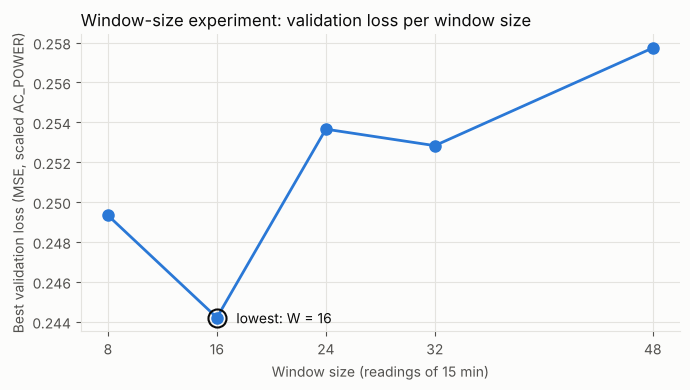

In [5]:
best_W = int(experiment['val loss (MSE, scaled)'].idxmin())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(experiment.index, experiment['val loss (MSE, scaled)'], color=BLUE, marker='o', markersize=8)
ax.plot(best_W, experiment.loc[best_W, 'val loss (MSE, scaled)'], 'o', markersize=13,
        markerfacecolor='none', markeredgecolor=INK, markeredgewidth=1.5)
ax.annotate(f'lowest: W = {best_W}', (best_W, experiment.loc[best_W, 'val loss (MSE, scaled)']),
            textcoords='offset points', xytext=(14, -4), ha='left', color=INK)
ax.set_xticks(WINDOW_SIZES)
ax.set_xlabel('Window size (readings of 15 min)')
ax.set_ylabel('Best validation loss (MSE, scaled AC_POWER)')
ax.set_title('Window-size experiment: validation loss per window size', loc='left')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'window_size_experiment.png'), dpi=150)
plt.show()

## Step 2 — Choose the window by validation loss (one-line justification)

The rule is simple: the window with the **lowest validation loss** wins. Validation data was not used to
update the weights, so it is a fair judge between the window sizes. Test data is not looked at here.

In [6]:
second_W = int(experiment['val loss (MSE, scaled)'].drop(best_W).idxmin())
gap_pct = 100 * (experiment.loc[second_W, 'val loss (MSE, scaled)'] / experiment.loc[best_W, 'val loss (MSE, scaled)'] - 1)

justification = (
    f'Window size {best_W} ({best_W * 15 / 60:g} h of history) was selected because it gave the lowest '
    f'validation loss (MSE {experiment.loc[best_W, "val loss (MSE, scaled)"]:.4f}, RMSE '
    f'{experiment.loc[best_W, "val RMSE (kW)"]:.1f} kW) among {WINDOW_SIZES}, '
    f'{gap_pct:.1f}% lower than the next best (W = {second_W}).')

with open(os.path.join(OUT_DIR, 'window_justification.txt'), 'w') as f:
    f.write(justification + '\n')
print(justification)

Window size 16 (4 h of history) was selected because it gave the lowest validation loss (MSE 0.2442, RMSE 200.1 kW) among [8, 16, 24, 32, 48], 2.1% lower than the next best (W = 8).


## Step 3 — Build the LSTM with the chosen window

Same architecture as in the experiment. `model.summary()` shows the layers and the number of weights:

- LSTM(64) on 3 inputs: 4 gates × (64 × (3 + 64) + 64) = **17,408** weights
- LSTM(32) on 64 inputs: 4 gates × (32 × (64 + 32) + 32) = **12,416** weights
- Dense(1) on 32 inputs: 32 + 1 = **33** weights

In [7]:
keras.utils.set_random_seed(SEED)
model = build_lstm(best_W)
model.summary()

with open(os.path.join(OUT_DIR, 'model_summary.txt'), 'w') as f:
    model.summary(print_fn=lambda line, **kwargs: f.write(line + '\n'))

Model: "lstm_window_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 16, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

## Step 4 — Train on ALL training data (faults included); validation for early stopping

As Dr. Mai asked, **nothing is removed from the training data**: daytime readings with zero or unusually
low power (possible faults) stay in. The model learns from the data as it really is.

Validation data is only used to decide **when to stop**: after every epoch the validation loss is checked,
training stops when it has not improved for `PATIENCE` epochs, and the best epoch's weights are restored.
Every epoch is written to `training_log.csv`.

In [8]:
data = build_windows(clean, best_W)
X_tr, y_tr, meta_tr = data['train']
targets = meta_tr.merge(clean[['SOURCE_KEY', 'DATE_TIME', 'IRRADIATION']], on=['SOURCE_KEY', 'DATE_TIME'])
low_power = (targets[TARGET] == 0) & (targets['IRRADIATION'] > 0.2)
print(f'Training windows: {len(y_tr):,} — of which {low_power.sum():,} have AC_POWER = 0 '
      f'while irradiation > 0.2 (kept in training)\n')

log_path = os.path.join(OUT_DIR, 'training_log.csv')
history = fit_model(model, data, [keras.callbacks.CSVLogger(log_path)]).history
model.save(os.path.join(OUT_DIR, 'lstm_model.keras'))

best_epoch = int(np.argmin(history['val_loss']))
print(f'\nStopped after {len(history["val_loss"])} epochs; best epoch = {best_epoch + 1} '
      f'(val loss {history["val_loss"][best_epoch]:.4f}). Same as in Step 1: '
      f'{np.isclose(history["val_loss"][best_epoch], experiment.loc[best_W, "val loss (MSE, scaled)"])}')

Training windows: 47,289 — of which 2,811 have AC_POWER = 0 while irradiation > 0.2 (kept in training)

Epoch 1/100


185/185 - 7s - 37ms/step - loss: 0.4906 - val_loss: 0.2846


Epoch 2/100


185/185 - 5s - 28ms/step - loss: 0.4385 - val_loss: 0.2698


Epoch 3/100


...

Epoch 15/100


185/185 - 5s - 25ms/step - loss: 0.3701 - val_loss: 0.2736


Epoch 16/100


185/185 - 5s - 25ms/step - loss: 0.3679 - val_loss: 0.2793



Stopped after 16 epochs; best epoch = 6 (val loss 0.2442). Same as in Step 1: True


## Step 5 — Training vs validation loss, best epoch marked

How to read it:
- both curves going down = the model is learning
- validation curve turning up while training keeps going down = overfitting → early stopping prevents it
- training loss is measured **with** dropout switched on, validation loss **without** it, so the training
  curve can sit above the validation curve; that is normal for models with dropout.

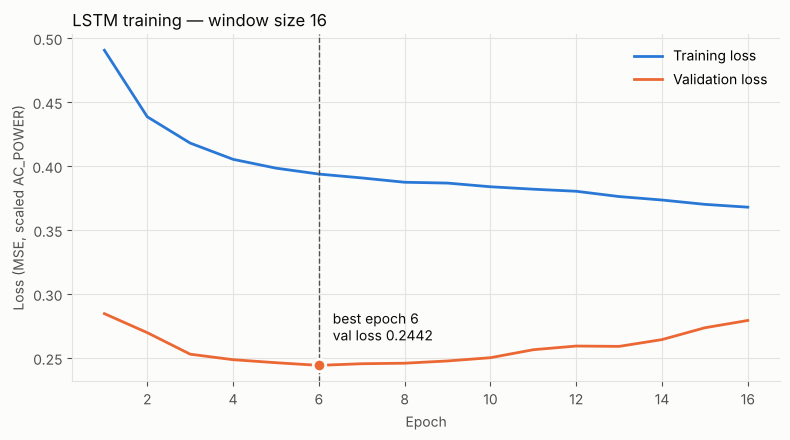

In [9]:
epochs = np.arange(1, len(history['loss']) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs, history['loss'], color=BLUE, label='Training loss')
ax.plot(epochs, history['val_loss'], color=ORANGE, label='Validation loss')
ax.axvline(best_epoch + 1, color=INK_2, linestyle='--', linewidth=1)
ax.plot(best_epoch + 1, history['val_loss'][best_epoch], 'o', color=ORANGE, markersize=9,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f'best epoch {best_epoch + 1}\nval loss {history["val_loss"][best_epoch]:.4f}',
            (best_epoch + 1, history['val_loss'][best_epoch]), textcoords='offset points',
            xytext=(10, 18), color=INK)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE, scaled AC_POWER)')
ax.set_title(f'LSTM training — window size {best_W}', loc='left')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'loss_curve.png'), dpi=150)
plt.show()

## Step 6 — Predict `AC_POWER` for train / validation / test and convert back to kW

The model outputs scaled values; `target_scaler.inverse_transform` turns them back into kW
($x = z \cdot \sigma + \mu$, with $\mu$, $\sigma$ from the training data).

Each file has one row per predicted reading, sorted by inverter and time, with the **actual** and the
**predicted** value side by side. These are the two lines Notebook 3 will turn into 0/1.

In [10]:
predictions = {}
for split in SPLITS:
    X, y, meta = data[split]
    pred_z = model.predict(X, batch_size=2048, verbose=0).ravel()
    out = meta.rename(columns={TARGET: 'ACTUAL_AC_POWER_kW'})
    out['PREDICTED_AC_POWER_kW'] = target_scaler.inverse_transform(pred_z[:, None]).ravel()
    out = out.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
    out.to_csv(os.path.join(OUT_DIR, f'prediction_{split}.csv'), index=False)
    predictions[split] = out
    print(f'{split:5s}: {len(out):,} predictions | predicted range {out.PREDICTED_AC_POWER_kW.min():.1f} '
          f'to {out.PREDICTED_AC_POWER_kW.max():.1f} kW | negative predictions: '
          f'{(out.PREDICTED_AC_POWER_kW < 0).sum()}')

predictions['test'].head()

train: 47,289 predictions | predicted range -23.3 to 1114.8 kW | negative predictions: 468


val  : 11,968 predictions | predicted range -8.5 to 1100.5 kW | negative predictions: 154


test : 11,440 predictions | predicted range -7.1 to 1090.8 kW | negative predictions: 44


,PLANT_ID,SOURCE_KEY,DATE_TIME,ACTUAL_AC_POWER_kW,PREDICTED_AC_POWER_kW
0,4135001,1BY6WEcLGh8j5v7,2020-06-13 05:45:00,0.000000,7.691406
1,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:00:00,9.162500,10.454895
2,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:15:00,33.228571,42.167816
3,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:30:00,55.037500,76.943359
4,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:45:00,102.142857,104.434875


## Step 7 — RMSE and MAE (kW) for each split

$\text{RMSE} = \sqrt{\frac{1}{n}\sum (y - \hat y)^2}$ punishes big errors more;
$\text{MAE} = \frac{1}{n}\sum |y - \hat y|$ is the average error in kW.

The report uses this guide: RMSE below 10–15% of the data range = acceptable forecasting accuracy,
so RMSE as % of the actual range is shown too.

In [11]:
def error_metrics(df):
    err = df['ACTUAL_AC_POWER_kW'] - df['PREDICTED_AC_POWER_kW']
    value_range = df['ACTUAL_AC_POWER_kW'].max() - df['ACTUAL_AC_POWER_kW'].min()
    rmse = np.sqrt((err ** 2).mean())
    return pd.Series({'readings': len(df), 'RMSE (kW)': rmse, 'MAE (kW)': err.abs().mean(),
                      'RMSE % of range': 100 * rmse / value_range})

metrics = pd.DataFrame({s: error_metrics(predictions[s]) for s in SPLITS}).T
metrics.index.name = 'split'
metrics.to_csv(os.path.join(OUT_DIR, 'metrics.csv'))
display(metrics.round(2))

print('Per plant (extra detail):')
pd.concat({s: predictions[s].groupby('PLANT_ID').apply(error_metrics, include_groups=False)
           for s in SPLITS}).round(2)

,readings,RMSE (kW),MAE (kW),RMSE % of range
split,,,,
train,47289.0,249.37,156.17,17.75
val,11968.0,200.14,121.47,14.75
test,11440.0,213.81,133.36,15.15


Per plant (extra detail):


readings  RMSE (kW)  MAE (kW)  RMSE % of range
      PLANT_ID                                                
train 4135001    22675.0     153.02    104.24            10.89
      4136001    24614.0     312.90    204.00            22.58
val   4135001     5786.0     121.90     84.15             8.99
      4136001     6182.0     252.26    156.40            18.59
test  4135001     5434.0     158.86    106.82            11.26
      4136001     6006.0     253.47    157.37            19.08

## Step 8 — Save and zip outputs

| File | Content | Used by |
|---|---|---|
| `window_size_experiment.csv` / `.png` | Step 1 results | report |
| `window_justification.txt` | Step 2 sentence | report |
| `model_summary.txt` | Step 3 architecture | report |
| `training_log.csv` | Step 4 loss per epoch | report |
| `loss_curve.png` | Step 5 plot | report |
| `lstm_model.keras` | trained model | re-use without retraining |
| `prediction_train/val/test.csv` | actual + predicted kW per reading | **Notebook 3** |
| `metrics.csv` | Step 7 table | report |

In [ ]:
experiment.to_csv(os.path.join(OUT_DIR, 'window_size_experiment.csv'))

shutil.make_archive('step2_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:30s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('step2_outputs.zip')    # keep this file: Notebook 3 needs it